# Setup

In [ ]:
# This takes a long time (do this just once!)
# https://ajwheeler.github.io/Korg.jl/stable/install/#Using-Korg-from-Python
# import juliapkg
# juliapkg.add("Korg", "acafc109-a718-429c-b0e5-afd7f8c7ae46")
# juliapkg.resolve()

In [ ]:
# --- Imports and Julia/Korg setup ------------------------------------------------
import os
import math
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

from juliacall import Main as jl
jl.seval("using Korg")
Korg = jl.Korg

# --- Matplotlib style ------------------------------------------------------------
plt.rcParams.update({
    "xtick.top": True,
    "ytick.right": True,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "font.size": 14,
    "font.family": "sans-serif",
    "axes.labelsize": 14,
    "axes.titlesize": 14,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "xtick.minor.visible": True,
    "ytick.minor.visible": True,
    "xtick.major.size": 6,
    "ytick.major.size": 6,
    "xtick.minor.size": 2,
    "ytick.minor.size": 2,
    #"axes.spines.top": False,
    #"axes.spines.right": False,
    "legend.frameon": False
    #"axes.grid" : True,
    #"grid.color": "gray",
    #"grid.linestyle": "--",
    #"grid.linewidth": 0.5,
    #"grid.alpha": 0.3,
})

# Generating data

In [ ]:
# --- Physical ranges and safety constraints -------------------------------------
# Sources for Teff range:
# https://www.pas.rochester.edu/~emamajek/EEM_dwarf_UBVIJHK_colors_Teff.txt

EFFECTIVE_TEMP_RANGE_K = (2350.0, 3850.0)      # Teff in Kelvin
METALLICITY_FEH_RANGE = (-0.5, 0.5)           # [Fe/H] in dex
RADIUS_RANGE_RSUN = (0.102, 0.588)        # stellar radius in R_sun
MASS_RANGE_MSUN = (0.079, 0.57)         # stellar mass in M_sun

In [ ]:
# --- Helpers: log g and radius bounds given mass --------------------------------
def compute_logg_from_mass_radius(mass_msun, radius_rsun):
    """
    Compute surface gravity log g (cgs) from mass and radius in solar units.
    Formula: log10(g) = log10(M/Msun) - 2*log10(R/Rsun) + 4.437
    Ref: https://adsabs.harvard.edu/full/2005MSAIS...8..130S
    """
    return math.log10(mass_msun) - 2.0 * math.log10(radius_rsun) + 4.437

In [ ]:
def generate_synthetic_spectra_dataset(num_samples, wavelength_window_A=(8800.0, 8835.0), max_draw_attempts=500,show_progress=True):
    records = []
    pbar = tqdm(total=num_samples, desc="Synthesizing spectra...", unit="sample") if show_progress else None

    while len(records) < num_samples:
        attempts = 0
        while attempts < max_draw_attempts:
            attempts += 1

            # Sample stellar parameters
            teff_K = float(np.random.uniform(*EFFECTIVE_TEMP_RANGE_K))
            feh_dex = float(np.random.uniform(*METALLICITY_FEH_RANGE))
            mass_msun = float(np.random.uniform(*MASS_RANGE_MSUN))
            radius_rsun = float(np.random.uniform(*RADIUS_RANGE_RSUN))
            logg_cgs = compute_logg_from_mass_radius(mass_msun, radius_rsun)

            try:
                # Korg returns wavelength, flux, and continuum arrays
                wavelengths_A, flux_norm, cont_norm = Korg.synth(
                    Teff=teff_K, logg=logg_cgs, M_H=feh_dex, wavelengths=wavelength_window_A
                )
                records.append({
                    "Teff_K": teff_K,
                    "logg_cgs": logg_cgs,
                    "FeH_dex": feh_dex,
                    "Mass_Msun": mass_msun,
                    "Radius_Rsun": radius_rsun,
                    "wavelength_A": wavelengths_A,
                    "flux": flux_norm,
                    "continuum": cont_norm,
                })
                if pbar:
                    pbar.update(1)
                break
            except Exception:
                continue

        if attempts >= max_draw_attempts:
            if pbar:
                pbar.close()
            raise RuntimeError("Could not draw a valid point")

    if pbar:
        pbar.close()
    return records

In [ ]:
# --- Generate data ---------------------------------------------------------------
NUM_SAMPLES = 5_000
data = generate_synthetic_spectra_dataset(num_samples=NUM_SAMPLES)

Synthesizing spectra...: 100%|██████████| 5000/5000 [55:11<00:00,  1.51sample/s] 


In [ ]:
# --- Build DataFrame with arrays per row ----------------------------------------
df_spectra = pd.DataFrame([{
    "Teff_K": s["Teff_K"],
    "logg_cgs": s["logg_cgs"],
    "FeH_dex": s["FeH_dex"],
    "Mass_Msun": s["Mass_Msun"],
    "Radius_Rsun": s["Radius_Rsun"],
    "wavelength_A": s["wavelength_A"],
    "flux": s["flux"],
    "continuum": s["continuum"]} for s in data])

df_spectra.head()

,Teff_K,logg_cgs,FeH_dex,Mass_Msun,Radius_Rsun,wavelength_A,flux,continuum
0,3005.690563,4.549996,-0.407823,0.093345,0.268255,"[8800.0, 8800.01, 8800.02, 8800.03, 8800.03999...","[0.9997130002738347, 0.9997125438691027, 0.999...","[474392.1136720313, 474392.1379970093, 474392...."
1,3500.506842,4.738027,-0.069822,0.472312,0.485961,"[8800.0, 8800.01, 8800.02, 8800.03, 8800.03999...","[0.9989975141114272, 0.998995375824019, 0.9989...","[846037.9208540168, 846037.433464546, 846036.9..."
2,3614.178935,5.336247,0.285490,0.416655,0.229227,"[8800.0, 8800.01, 8800.02, 8800.03, 8800.03999...","[0.9975585336167688, 0.9975535752299022, 0.997...","[1033283.7462387083, 1033282.9289557105, 10332..."
3,3684.755032,4.914015,0.188288,0.320993,0.327145,"[8800.0, 8800.01, 8800.02, 8800.03, 8800.03999...","[0.9978451268491023, 0.9978405973319374, 0.997...","[1058675.0232963974, 1058674.1569517695, 10586..."
4,3031.622930,4.592513,-0.485033,0.373166,0.510734,"[8800.0, 8800.01, 8800.02, 8800.03, 8800.03999...","[0.9997045677881402, 0.9997040891156536, 0.999...","[483859.99259478867, 483860.00691281876, 48386..."


# Visualizing the data

In [ ]:
def plot_single_spectrum(df_spectra, row_index):
    # Select row:
    row = df_spectra.iloc[row_index]
    wavelength_A = np.asarray(row["wavelength_A"], dtype=float)
    flux = np.asarray(row["flux"], dtype=float)

    plt.figure(figsize=(10, 4))
    plt.plot(wavelength_A, flux)
    plt.xlabel(r"Wavelength $\lambda$ [$\AA$]")
    plt.ylabel("continuum-normalized flux")
    title = f"Teff={row['Teff_K']:.0f} K logg={row['logg_cgs']:.2f}  [Fe/H]={row['FeH_dex']:.2f}"
    plt.title(title, loc="left", fontweight='bold')
    plt.tight_layout()

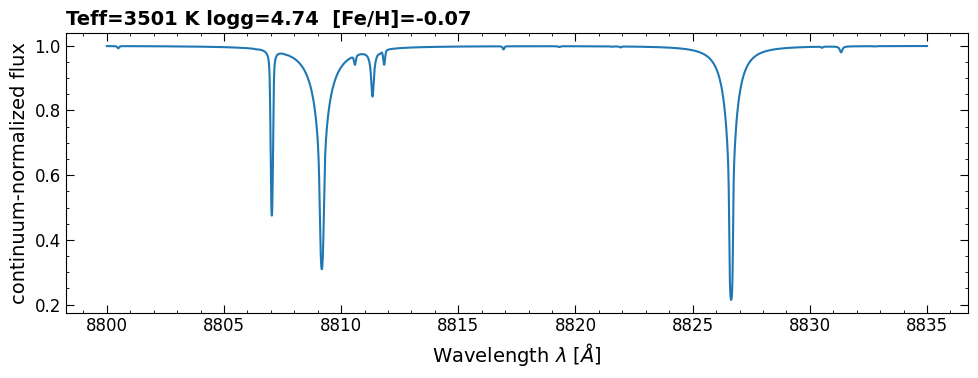

In [ ]:
plot_single_spectrum(df_spectra,1)

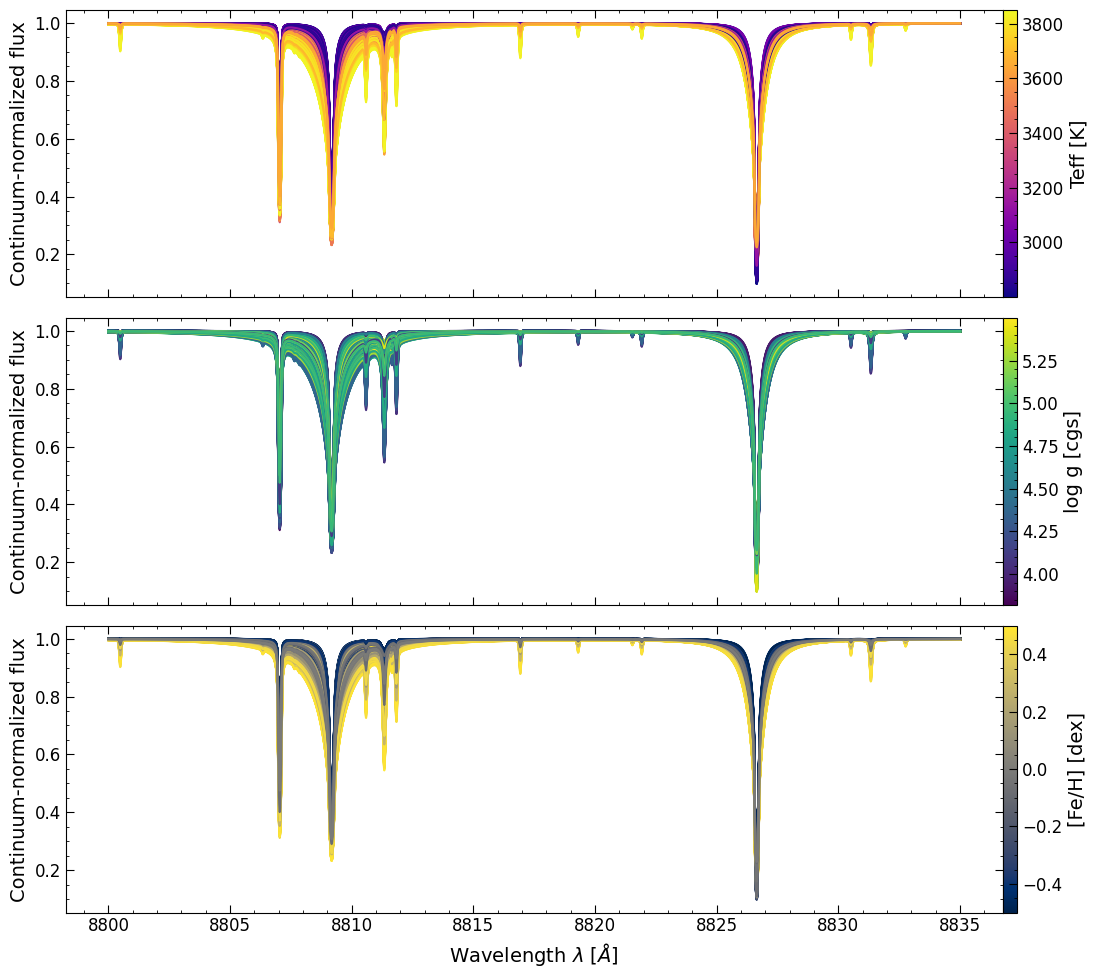

In [ ]:
# --- Plot: three stacks colored by Teff, log g, [Fe/H] --------------------------
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

# Panel 1 colored by Teff
norm_teff = Normalize(vmin=df_spectra["Teff_K"].min(), vmax=df_spectra["Teff_K"].max())
cmap_teff = plt.cm.plasma
for _, row in df_spectra.iterrows():
    axes[0].plot(np.asarray(row["wavelength_A"]), np.asarray(row["flux"]),
                color=cmap_teff(norm_teff(row["Teff_K"])))
sm = ScalarMappable(norm=norm_teff, cmap=cmap_teff)
fig.colorbar(sm, ax=axes[0], label="Teff [K]", pad=0)
axes[0].set_ylabel("Continuum-normalized flux")

# Panel 2 colored by log g
norm_logg = Normalize(vmin=df_spectra["logg_cgs"].min(), vmax=df_spectra["logg_cgs"].max())
cmap_logg = plt.cm.viridis
for _, row in df_spectra.iterrows():
    axes[1].plot(np.asarray(row["wavelength_A"]), np.asarray(row["flux"]),
                color=cmap_logg(norm_logg(row["logg_cgs"])))
sm = ScalarMappable(norm=norm_logg, cmap=cmap_logg)
fig.colorbar(sm, ax=axes[1], label="log g [cgs]", pad=0)
axes[1].set_ylabel("Continuum-normalized flux")

# Panel 3 colored by [Fe/H]
norm_feh = Normalize(vmin=df_spectra["FeH_dex"].min(), vmax=df_spectra["FeH_dex"].max())
cmap_feh = plt.cm.cividis
for _, row in df_spectra.iterrows():
    axes[2].plot(np.asarray(row["wavelength_A"]), np.asarray(row["flux"]),
                color=cmap_feh(norm_feh(row["FeH_dex"])))
sm = ScalarMappable(norm=norm_feh, cmap=cmap_feh)
fig.colorbar(sm, ax=axes[2], label="[Fe/H] [dex]", pad=0)

axes[2].set_xlabel(r"Wavelength $\lambda$ [$\AA$]")
axes[2].set_ylabel("Continuum-normalized flux")
plt.tight_layout()

In [ ]:
# Don't modify the original dataframe
df_parquet = df_spectra.copy()

In [ ]:
# --- Save to Parquet: convert arrays to Arrow list columns ----------------------
for col in ["wavelength_A", "flux", "continuum"]:
    df_parquet[col] = df_parquet[col].apply(lambda x: np.asarray(x, dtype=np.float32).tolist())

# Requires pyarrow installed
#   pip install pyarrow
BASE_PATH = "../data"
FILENAME = "all_samples.parquet"
full_path = os.path.join(BASE_PATH, FILENAME)

if os.path.exists(full_path):
    counter = 1
    while os.path.exists(os.path.join(BASE_PATH, f"all_samples{counter}.parquet")):
        counter += 1
    full_path = os.path.join(BASE_PATH, f"all_samples{counter}.parquet")

df_parquet.to_parquet(full_path, engine="pyarrow", index=False)

In [ ]:
# --- Read back --------------------------------------------------
df_check = pd.read_parquet(full_path)
df_check.head()

,Teff_K,logg_cgs,FeH_dex,Mass_Msun,Radius_Rsun,wavelength_A,flux,continuum
0,3005.690563,4.549996,-0.407823,0.093345,0.268255,"[8800.0, 8800.009765625, 8800.01953125, 8800.0...","[0.9997130036354065, 0.9997125267982483, 0.999...","[474392.125, 474392.125, 474392.15625, 474392...."
1,3500.506842,4.738027,-0.069822,0.472312,0.485961,"[8800.0, 8800.009765625, 8800.01953125, 8800.0...","[0.9989975094795227, 0.9989953637123108, 0.998...","[846037.9375, 846037.4375, 846036.9375, 846036..."
2,3614.178935,5.336247,0.285490,0.416655,0.229227,"[8800.0, 8800.009765625, 8800.01953125, 8800.0...","[0.9975585341453552, 0.9975535869598389, 0.997...","[1033283.75, 1033282.9375, 1033282.125, 103328..."
3,3684.755032,4.914015,0.188288,0.320993,0.327145,"[8800.0, 8800.009765625, 8800.01953125, 8800.0...","[0.9978451132774353, 0.9978405833244324, 0.997...","[1058675.0, 1058674.125, 1058673.25, 1058672.3..."
4,3031.622930,4.592513,-0.485033,0.373166,0.510734,"[8800.0, 8800.009765625, 8800.01953125, 8800.0...","[0.9997045397758484, 0.9997040629386902, 0.999...","[483860.0, 483860.0, 483860.03125, 483860.0312..."


In [ ]:
def plot_histogram(df, column, value_range, step, xlabel=None, ylabel="Count", figsize=(10, 4), color="tab:blue"):
    bins = np.arange(value_range[0], value_range[1] + step, step)

    plt.figure(figsize=figsize)
    df[column].hist(grid=False, ec="k", bins=bins, color=color)
    plt.xlabel(xlabel if xlabel else column)
    plt.ylabel(ylabel)
    plt.xticks(bins);

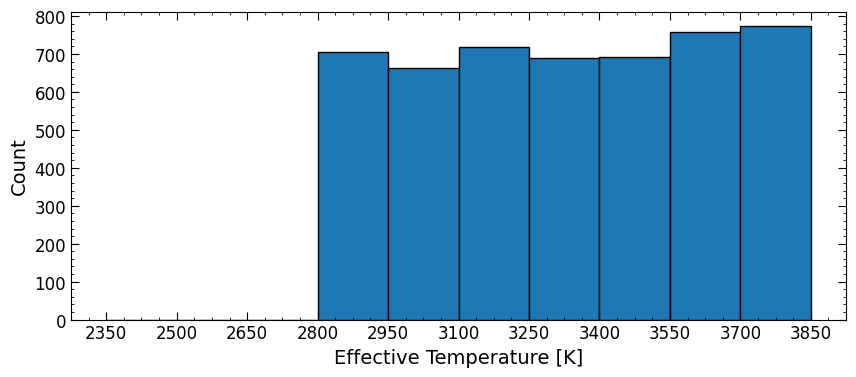

In [ ]:
plot_histogram(df_check, "Teff_K", EFFECTIVE_TEMP_RANGE_K, 150, xlabel="Effective Temperature [K]")

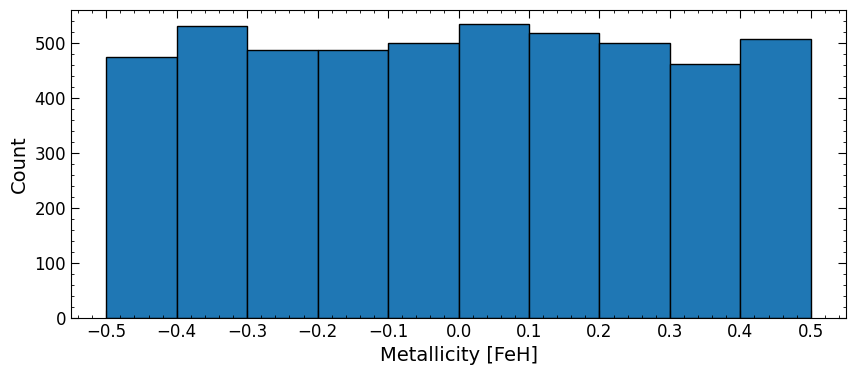

In [ ]:
plot_histogram(df_check, "FeH_dex", METALLICITY_FEH_RANGE, 0.1, xlabel="Metallicity [FeH]")

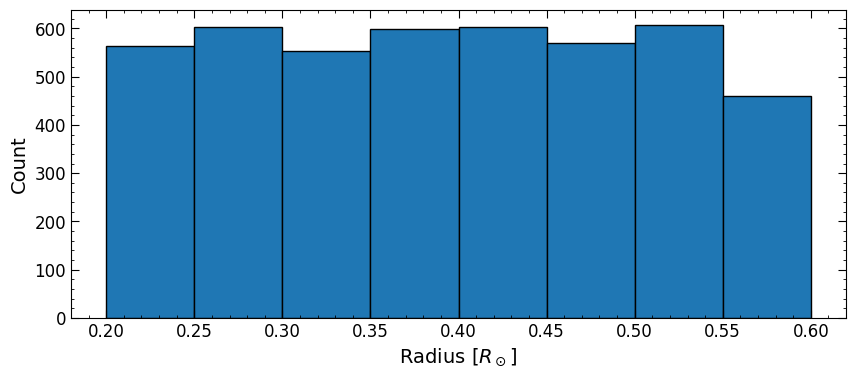

In [ ]:
plot_histogram(df_check, "Radius_Rsun", (0.2, 0.6), 0.05, xlabel=r"Radius [$R_\odot$]")

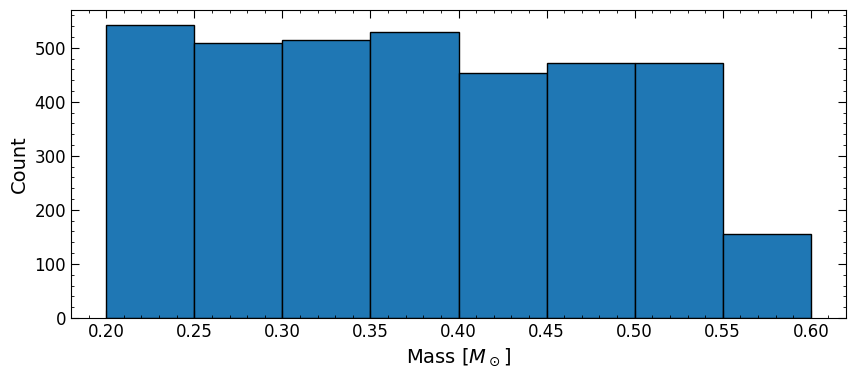

In [ ]:
plot_histogram(df_check, "Mass_Msun", (0.2, 0.6), 0.05, xlabel=r"Mass [$M_\odot$]")

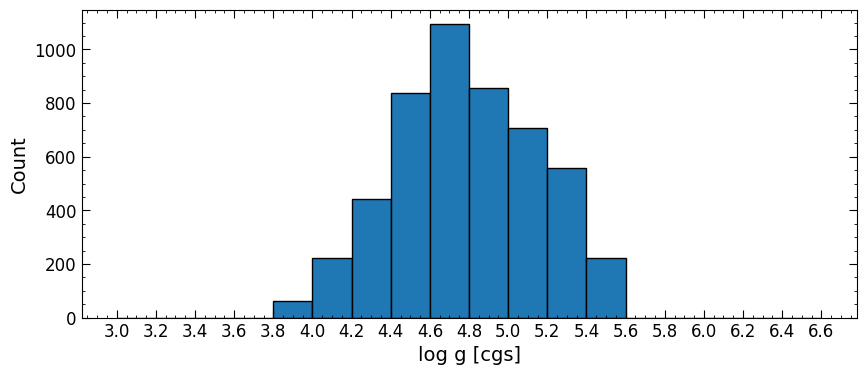

In [ ]:
plot_histogram(df_check, "logg_cgs", (3, 6.5), 0.2, xlabel="log g [cgs]")